<a href="https://colab.research.google.com/github/SrustiUB/Data-Science/blob/main/Kalman_filter_trading.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 90.1/90.1 kB 798.3 kB/s eta 0:00:00
TCS-INFY KALMAN FILTER PAIRS TRADING

Data shape: (1975, 2)

First observations:
                   TCS         INFY
Date                               
2018-01-01  406.448975  1063.442749
2018-01-02  404.934845  1057.653687
2018-01-03  401.631561  1060.648560
2018-01-04  399.311340  1068.065186
2018-01-05  397.974304  1080.968140

Last observations:
                    TCS         INFY
Date                                
2025-12-23  1632.963745  3189.922363
2025-12-24  1628.167480  3198.595947
2025-12-26  1621.022095  3161.010986
2025-12-29  1609.863525  3133.544434
2025-12-30  1587.252808  3129.015381

DATA QUALITY CHECK
Missing values:
TCS     0
INFY    0
dtype: int64

Infinite values:
TCS     0
INFY    0
dtype: int64

RETURN CORRELATION
TCS-INFY Return Correlation: 0.6383

ENGLE-GRANGER COINTEGRATION TEST
Cointegration Statistic: -3.0731
P-value: 0.093840

Critical Values:
1%:  -3.9020
5%:  -3.3392
10%

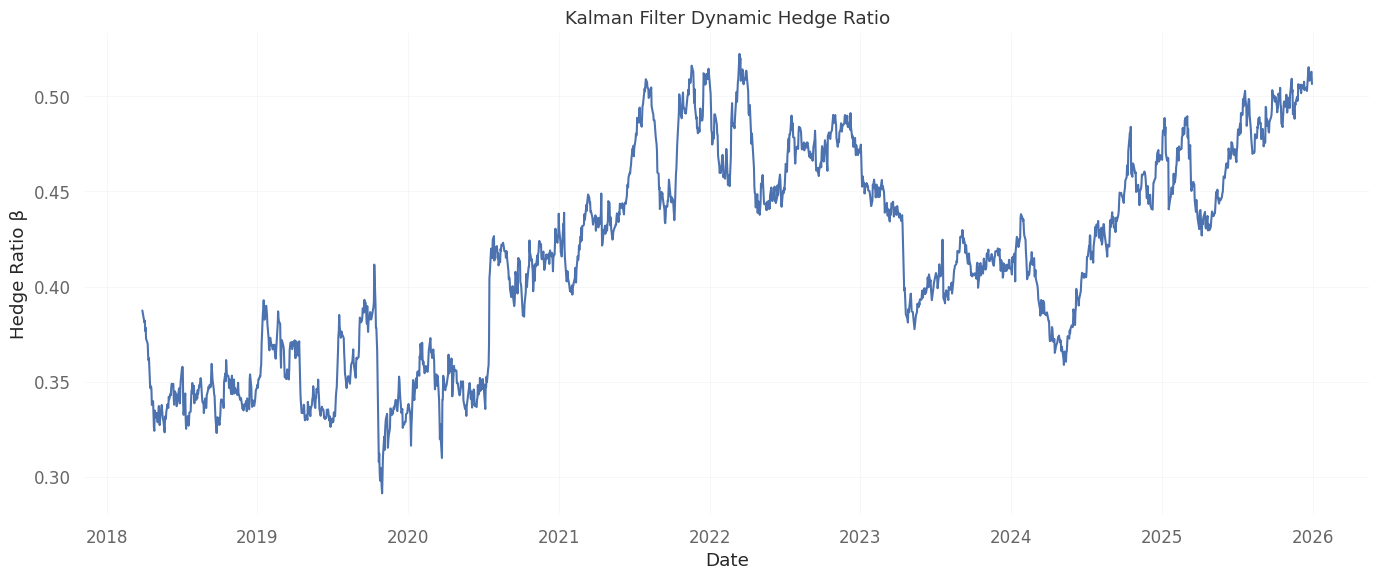

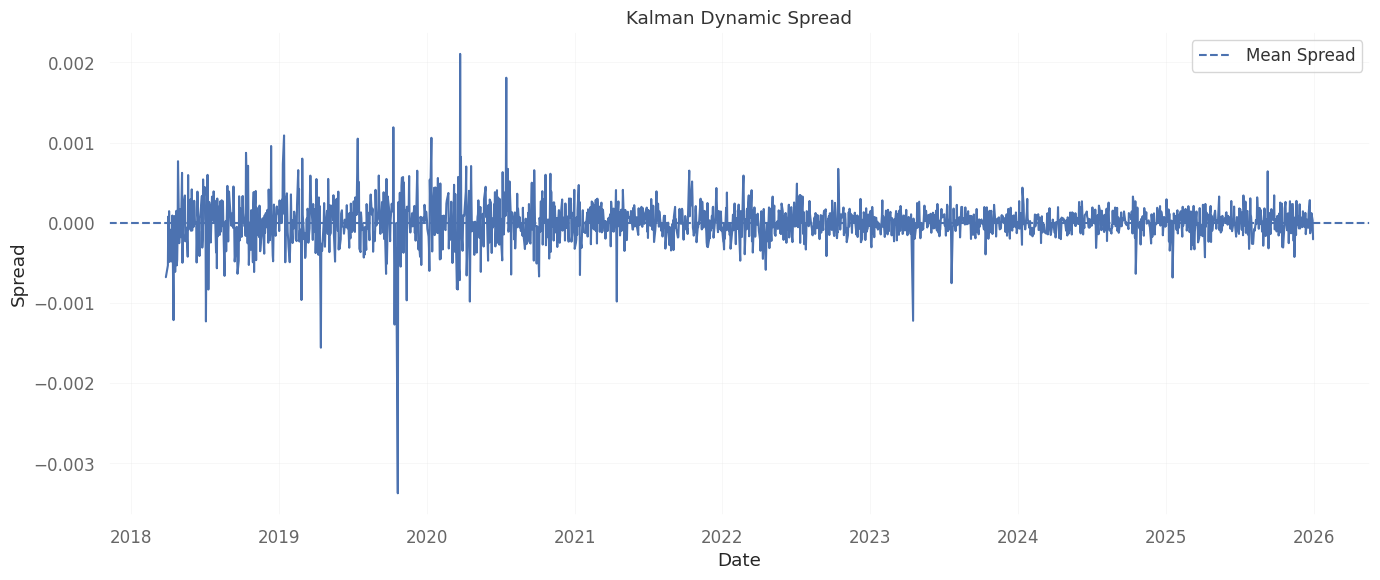

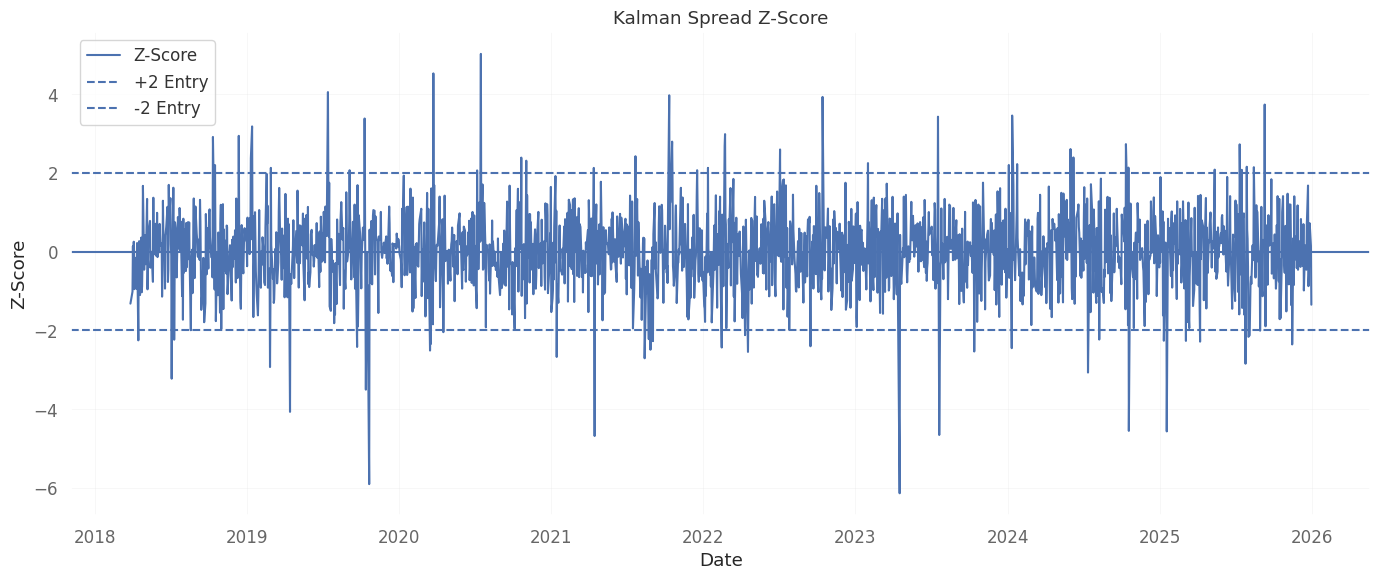


PART 1 COMPLETE

Saved:
TCS_INFY_Kalman_Hedge_Ratio.png
TCS_INFY_Kalman_Spread.png
TCS_INFY_Kalman_ZScore.png
TCS_INFY_Kalman_Part1_Data.csv


In [ ]:
# ================================================================
# KALMAN FILTER PAIRS TRADING
# PART 1: DATA + COINTEGRATION + KALMAN FILTER
# TCS vs INFY
# ================================================================

!pip -q install yfinance quantstats statsmodels

# ================================================================
# IMPORTS
# ================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
import quantstats as qs

from statsmodels.tsa.stattools import coint

import warnings
warnings.filterwarnings("ignore")

plt.rcParams["figure.figsize"] = (14, 6)

# ================================================================
# PARAMETERS
# ================================================================

TICKER_Y = "TCS.NS"
TICKER_X = "INFY.NS"

START_DATE = "2018-01-01"
END_DATE = "2025-12-31"

LOOKBACK_Z = 60

ENTRY_Z = 2.0
EXIT_Z = 0.5

TRANSACTION_COST = 0.0005

# Kalman parameters
DELTA = 1e-5
OBSERVATION_VARIANCE = 1e-3

# ================================================================
# DOWNLOAD DATA
# ================================================================

print("=" * 70)
print("TCS-INFY KALMAN FILTER PAIRS TRADING")
print("=" * 70)

data = yf.download(
    [TICKER_Y, TICKER_X],
    start=START_DATE,
    end=END_DATE,
    auto_adjust=True,
    progress=False
)

prices = data["Close"].copy()

prices.columns = ["TCS", "INFY"]

prices = prices.dropna()

print("\nData shape:", prices.shape)

print("\nFirst observations:")
print(prices.head())

print("\nLast observations:")
print(prices.tail())

# ================================================================
# DATA QUALITY
# ================================================================

print("\n" + "=" * 70)
print("DATA QUALITY CHECK")
print("=" * 70)

print("Missing values:")
print(prices.isna().sum())

print("\nInfinite values:")
print(np.isinf(prices).sum())

# ================================================================
# RETURNS
# ================================================================

returns = prices.pct_change().dropna()

# ================================================================
# CORRELATION
# ================================================================

print("\n" + "=" * 70)
print("RETURN CORRELATION")
print("=" * 70)

correlation = (
    returns["TCS"]
    .corr(returns["INFY"])
)

print(
    f"TCS-INFY Return Correlation: "
    f"{correlation:.4f}"
)

# ================================================================
# COINTEGRATION
# ================================================================

print("\n" + "=" * 70)
print("ENGLE-GRANGER COINTEGRATION TEST")
print("=" * 70)

coint_stat, p_value, critical_values = coint(
    prices["TCS"],
    prices["INFY"]
)

print(
    f"Cointegration Statistic: "
    f"{coint_stat:.4f}"
)

print(
    f"P-value: "
    f"{p_value:.6f}"
)

print("\nCritical Values:")

print(
    f"1%:  {critical_values[0]:.4f}"
)

print(
    f"5%:  {critical_values[1]:.4f}"
)

print(
    f"10%: {critical_values[2]:.4f}"
)

if p_value < 0.05:

    print(
        "\n✓ Pair is cointegrated "
        "at the 5% level."
    )

else:

    print(
        "\n⚠ Pair is NOT cointegrated "
        "at the 5% level."
    )

# ================================================================
# KALMAN FILTER FUNCTION
# ================================================================

def kalman_filter(
    y,
    x,
    delta=1e-5,
    observation_variance=1e-3
):

    n = len(y)

    # State:
    # theta = [intercept, hedge_ratio]

    theta = np.zeros(2)

    # State covariance
    P = np.eye(2)

    # Observation variance
    R = observation_variance

    # State transition noise
    Q = (
        delta /
        (1 - delta)
        * np.eye(2)
    )

    intercept = np.zeros(n)

    hedge_ratio = np.zeros(n)

    spread = np.zeros(n)

    # ============================================================
    # KALMAN RECURSION
    # ============================================================

    for t in range(n):

        # --------------------------------------------------------
        # 1. Predict state
        # --------------------------------------------------------

        theta_pred = theta

        P_pred = P + Q

        # --------------------------------------------------------
        # 2. Observation vector
        # --------------------------------------------------------

        F = np.array(
            [
                1.0,
                x[t]
            ]
        )

        # --------------------------------------------------------
        # 3. Predict Y
        # --------------------------------------------------------

        y_pred = np.dot(
            F,
            theta_pred
        )

        # --------------------------------------------------------
        # 4. Prediction error
        # --------------------------------------------------------

        error = (
            y[t]
            -
            y_pred
        )

        # --------------------------------------------------------
        # 5. Prediction variance
        # --------------------------------------------------------

        S = (
            np.dot(
                F,
                np.dot(
                    P_pred,
                    F
                )
            )
            +
            R
        )

        # --------------------------------------------------------
        # 6. Kalman gain
        # --------------------------------------------------------

        K = (
            np.dot(
                P_pred,
                F
            )
            /
            S
        )

        # --------------------------------------------------------
        # 7. Update state
        # --------------------------------------------------------

        theta = (
            theta_pred
            +
            K * error
        )

        # --------------------------------------------------------
        # 8. Update covariance
        # --------------------------------------------------------

        P = (
            P_pred
            -
            np.outer(
                K,
                np.dot(
                    F,
                    P_pred
                )
            )
        )

        # --------------------------------------------------------
        # 9. Store parameters
        # --------------------------------------------------------

        intercept[t] = theta[0]

        hedge_ratio[t] = theta[1]

        # --------------------------------------------------------
        # 10. Dynamic spread
        # --------------------------------------------------------

        spread[t] = (
            y[t]
            -
            intercept[t]
            -
            hedge_ratio[t]
            * x[t]
        )

    return (
        intercept,
        hedge_ratio,
        spread
    )

# ================================================================
# APPLY KALMAN FILTER
# ================================================================

print("\n" + "=" * 70)
print("RUNNING KALMAN FILTER")
print("=" * 70)

intercept, hedge_ratio, spread = kalman_filter(
    prices["TCS"].values,
    prices["INFY"].values,
    DELTA,
    OBSERVATION_VARIANCE
)

prices["Intercept"] = intercept

prices["Hedge_Ratio"] = hedge_ratio

prices["Spread"] = spread

# ================================================================
# Z-SCORE
# ================================================================

prices["Spread_Mean"] = (
    prices["Spread"]
    .rolling(LOOKBACK_Z)
    .mean()
)

prices["Spread_STD"] = (
    prices["Spread"]
    .rolling(LOOKBACK_Z)
    .std()
)

prices["ZScore"] = (
    (
        prices["Spread"]
        -
        prices["Spread_Mean"]
    )
    /
    prices["Spread_STD"]
)

prices = prices.replace(
    [np.inf, -np.inf],
    np.nan
)

prices = prices.dropna()

# ================================================================
# SUMMARY
# ================================================================

print("\n" + "=" * 70)
print("KALMAN FILTER RESULTS")
print("=" * 70)

print(
    f"Initial Hedge Ratio: "
    f"{prices['Hedge_Ratio'].iloc[0]:.4f}"
)

print(
    f"Final Hedge Ratio:   "
    f"{prices['Hedge_Ratio'].iloc[-1]:.4f}"
)

print(
    f"Mean Hedge Ratio:    "
    f"{prices['Hedge_Ratio'].mean():.4f}"
)

print(
    f"Spread Mean: "
    f"{prices['Spread'].mean():.4f}"
)

print(
    f"Spread Std:  "
    f"{prices['Spread'].std():.4f}"
)

# ================================================================
# PLOT 1: DYNAMIC HEDGE RATIO
# ================================================================

plt.figure(figsize=(14, 6))

plt.plot(
    prices.index,
    prices["Hedge_Ratio"]
)

plt.title(
    "Kalman Filter Dynamic Hedge Ratio"
)

plt.xlabel("Date")

plt.ylabel("Hedge Ratio β")

plt.grid(True, alpha=0.3)

plt.tight_layout()

plt.savefig(
    "TCS_INFY_Kalman_Hedge_Ratio.png",
    dpi=200
)

plt.show()

# ================================================================
# PLOT 2: SPREAD
# ================================================================

plt.figure(figsize=(14, 6))

plt.plot(
    prices.index,
    prices["Spread"]
)

plt.axhline(
    prices["Spread"].mean(),
    linestyle="--",
    label="Mean Spread"
)

plt.title(
    "Kalman Dynamic Spread"
)

plt.xlabel("Date")

plt.ylabel("Spread")

plt.legend()

plt.grid(True, alpha=0.3)

plt.tight_layout()

plt.savefig(
    "TCS_INFY_Kalman_Spread.png",
    dpi=200
)

plt.show()

# ================================================================
# PLOT 3: Z-SCORE
# ================================================================

plt.figure(figsize=(14, 6))

plt.plot(
    prices.index,
    prices["ZScore"],
    label="Z-Score"
)

plt.axhline(
    ENTRY_Z,
    linestyle="--",
    label="+2 Entry"
)

plt.axhline(
    -ENTRY_Z,
    linestyle="--",
    label="-2 Entry"
)

plt.axhline(
    0,
    linestyle="-"
)

plt.title(
    "Kalman Spread Z-Score"
)

plt.xlabel("Date")

plt.ylabel("Z-Score")

plt.legend()

plt.grid(True, alpha=0.3)

plt.tight_layout()

plt.savefig(
    "TCS_INFY_Kalman_ZScore.png",
    dpi=200
)

plt.show()

# ================================================================
# SAVE PART 1 DATA
# ================================================================

prices.to_csv(
    "TCS_INFY_Kalman_Part1_Data.csv"
)

print("\n" + "=" * 70)
print("PART 1 COMPLETE")
print("=" * 70)

print("\nSaved:")
print("TCS_INFY_Kalman_Hedge_Ratio.png")
print("TCS_INFY_Kalman_Spread.png")
print("TCS_INFY_Kalman_ZScore.png")
print("TCS_INFY_Kalman_Part1_Data.csv")


FULL SAMPLE KALMAN PAIRS TRADING
Return              : -6.47%
CAGR                : -0.88%
Volatility          : 7.37%
Sharpe              : -0.08
Sortino             : -0.03
Max Drawdown        : -22.91%

SIGNAL DISTRIBUTION
Long Spread Signals : 54
Short Spread Signals: 49
Neutral             : 1813

70/30 OUT-OF-SAMPLE TEST

Training: 2018-03-28 → 2023-08-30
Testing:  2023-08-31 → 2025-12-30

OOS KALMAN PAIRS RESULTS
Return              : 16.83%
CAGR                : 7.89%
Volatility          : 6.60%
Sharpe              : 1.18
Sortino             : 1.29
Max Drawdown        : -3.76%

OOS TCS BUY & HOLD
Return              : 18.00%
CAGR                : 8.42%
Volatility          : 24.11%
Sharpe              : 0.46
Sortino             : 0.72
Max Drawdown        : -30.15%

OOS SIGNAL DISTRIBUTION
Long Spread Signals : 17
Short Spread Signals: 12
Neutral Signals     : 487

Approximate Signal Win Rate: 35.56%

GENERATING QUANTSTATS


QuantStats report saved:
TCS_INFY_Kalman_QuantStats.html


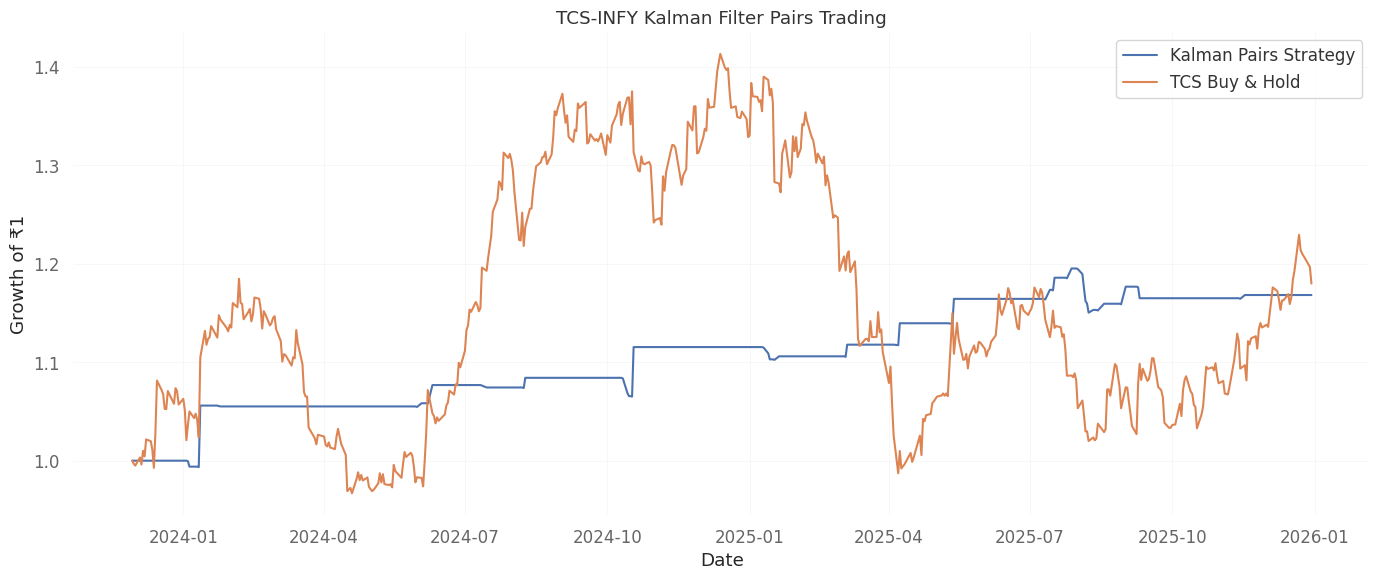

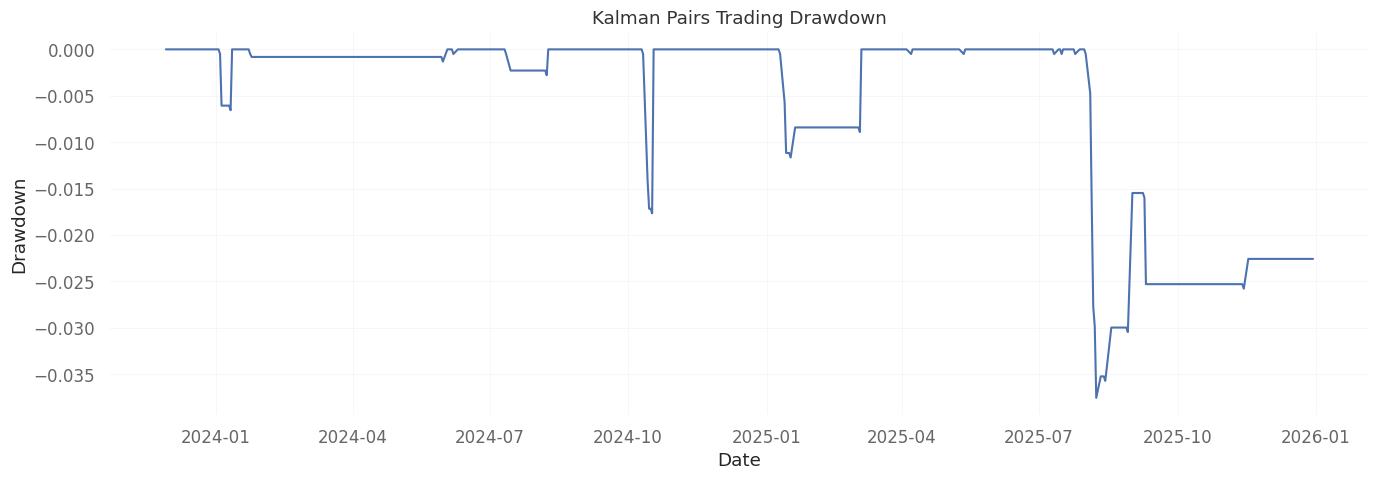

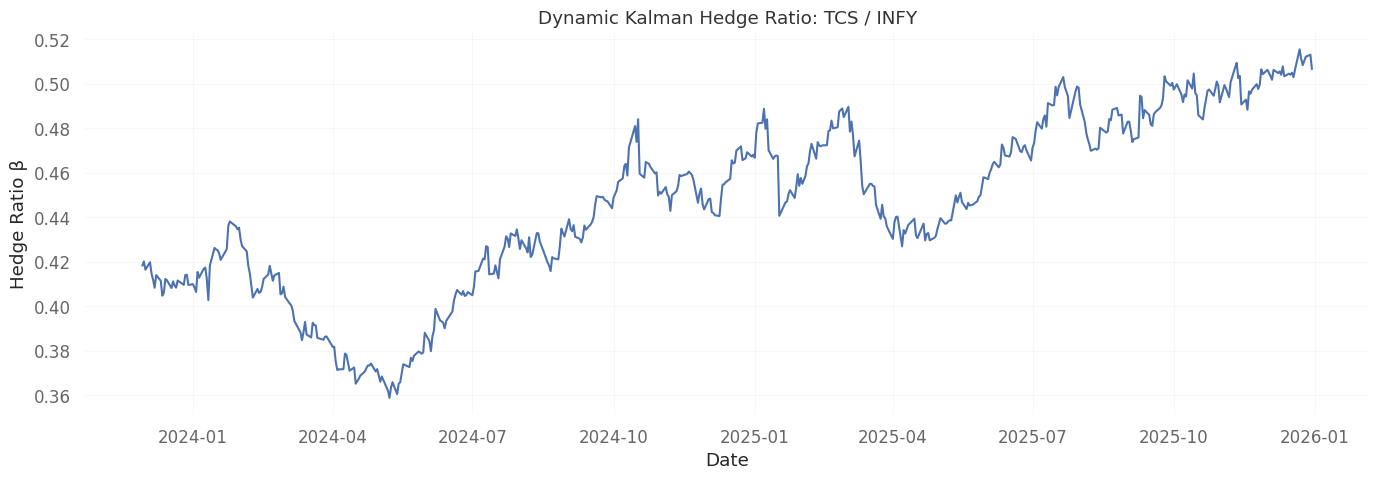

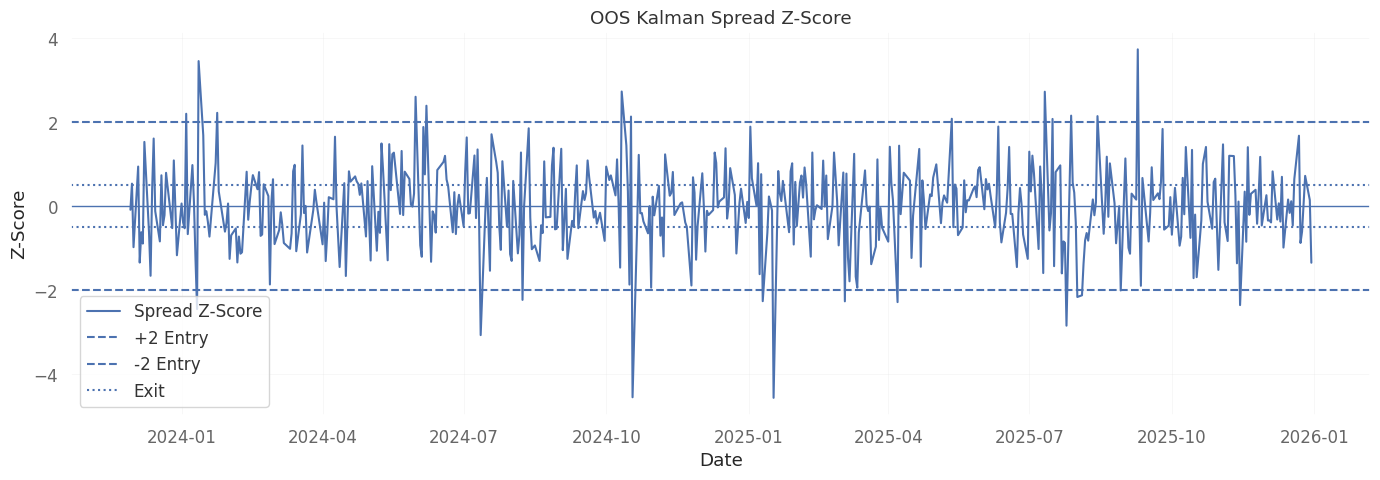


KALMAN FILTER PAIRS TRADING COMPLETE

Pair: TCS vs INFY
Cointegration p-value: 0.093840
OOS Return: 16.83%
OOS CAGR: 7.89%
OOS Volatility: 6.60%
OOS Sharpe: 1.18
OOS Sortino: 1.29
OOS Max Drawdown: -3.76%
Final Hedge Ratio: 0.5066

Files saved:
1. TCS_INFY_Kalman_OOS.csv
2. TCS_INFY_Kalman_QuantStats.html
3. TCS_INFY_Kalman_Equity.png
4. TCS_INFY_Kalman_Drawdown.png
5. TCS_INFY_Kalman_OOS_Hedge_Ratio.png
6. TCS_INFY_Kalman_OOS_ZScore.png

PROJECT COMPLETE


In [ ]:
# ================================================================
# KALMAN FILTER PAIRS TRADING
# PART 2: SIGNALS + BACKTEST + 70/30 OOS + QUANTSTATS
# TCS vs INFY
# ================================================================

# ================================================================
# SIGNAL FUNCTION
# ================================================================

def generate_signals(df, entry_z=2.0, exit_z=0.5):

    signals = pd.Series(
        0.0,
        index=df.index
    )

    position = 0

    for i in range(len(df)):

        z = df["ZScore"].iloc[i]

        # --------------------------------------------------------
        # LONG SPREAD
        # TCS relatively cheap
        # LONG TCS
        # SHORT INFY
        # --------------------------------------------------------

        if position == 0 and z < -entry_z:
            position = 1

        # --------------------------------------------------------
        # SHORT SPREAD
        # TCS relatively expensive
        # SHORT TCS
        # LONG INFY
        # --------------------------------------------------------

        elif position == 0 and z > entry_z:
            position = -1

        # --------------------------------------------------------
        # EXIT LONG
        # --------------------------------------------------------

        elif position == 1 and z > -exit_z:
            position = 0

        # --------------------------------------------------------
        # EXIT SHORT
        # --------------------------------------------------------

        elif position == -1 and z < exit_z:
            position = 0

        signals.iloc[i] = position

    return signals


# ================================================================
# FULL SAMPLE SIGNALS
# ================================================================

prices["Signal"] = generate_signals(
    prices,
    ENTRY_Z,
    EXIT_Z
)

# ================================================================
# POSITIONS
# ================================================================

# Signal = +1
# Long TCS
# Short beta × INFY

prices["TCS_Position"] = (
    prices["Signal"]
)

prices["INFY_Position"] = (
    -prices["Signal"]
    *
    prices["Hedge_Ratio"]
)

# ================================================================
# RETURNS
# ================================================================

prices["TCS_Return"] = (
    prices["TCS"]
    .pct_change()
)

prices["INFY_Return"] = (
    prices["INFY"]
    .pct_change()
)

# Use yesterday's signal to avoid look-ahead bias

prices["Gross_Return"] = (
    prices["TCS_Position"].shift(1)
    *
    prices["TCS_Return"]
    +
    prices["INFY_Position"].shift(1)
    *
    prices["INFY_Return"]
)

# ================================================================
# TRANSACTION COST
# ================================================================

prices["Position_Change"] = (
    prices["Signal"]
    .diff()
    .abs()
)

prices["Transaction_Cost"] = (
    prices["Position_Change"]
    *
    TRANSACTION_COST
)

prices["Strategy_Return"] = (
    prices["Gross_Return"]
    -
    prices["Transaction_Cost"]
)

prices["Strategy_Return"] = (
    prices["Strategy_Return"]
    .replace(
        [np.inf, -np.inf],
        np.nan
    )
    .fillna(0)
)

# ================================================================
# BUY & HOLD
# ================================================================

prices["Buy_Hold_Return"] = (
    prices["TCS_Return"]
    .fillna(0)
)

# ================================================================
# EQUITY CURVES
# ================================================================

prices["Strategy_Equity"] = (
    1 +
    prices["Strategy_Return"]
).cumprod()

prices["Buy_Hold_Equity"] = (
    1 +
    prices["Buy_Hold_Return"]
).cumprod()

# ================================================================
# PERFORMANCE FUNCTION
# ================================================================

def performance_metrics(returns):

    returns = returns.dropna()

    total_return = (
        (1 + returns).prod()
        - 1
    )

    years = len(returns) / 252

    if total_return > -1 and years > 0:

        cagr = (
            (1 + total_return)
            ** (1 / years)
            - 1
        )

    else:

        cagr = np.nan

    volatility = (
        returns.std()
        *
        np.sqrt(252)
    )

    if returns.std() != 0:

        sharpe = (
            returns.mean()
            /
            returns.std()
            *
            np.sqrt(252)
        )

    else:

        sharpe = np.nan

    downside = returns[
        returns < 0
    ]

    if (
        len(downside) > 1
        and downside.std() != 0
    ):

        sortino = (
            returns.mean()
            /
            downside.std()
            *
            np.sqrt(252)
        )

    else:

        sortino = np.nan

    equity = (
        1 + returns
    ).cumprod()

    running_max = equity.cummax()

    drawdown = (
        equity
        /
        running_max
        - 1
    )

    max_drawdown = drawdown.min()

    return {
        "Return": total_return,
        "CAGR": cagr,
        "Volatility": volatility,
        "Sharpe": sharpe,
        "Sortino": sortino,
        "Max Drawdown": max_drawdown
    }


# ================================================================
# FULL SAMPLE RESULTS
# ================================================================

full_metrics = performance_metrics(
    prices["Strategy_Return"]
)

print("\n" + "=" * 70)
print("FULL SAMPLE KALMAN PAIRS TRADING")
print("=" * 70)

for key, value in full_metrics.items():

    if key in ["Sharpe", "Sortino"]:

        print(
            f"{key:<20}: "
            f"{value:.2f}"
        )

    else:

        print(
            f"{key:<20}: "
            f"{value * 100:.2f}%"
        )

# ================================================================
# SIGNAL DISTRIBUTION
# ================================================================

print("\n" + "=" * 70)
print("SIGNAL DISTRIBUTION")
print("=" * 70)

print(
    "Long Spread Signals :",
    (prices["Signal"] == 1).sum()
)

print(
    "Short Spread Signals:",
    (prices["Signal"] == -1).sum()
)

print(
    "Neutral             :",
    (prices["Signal"] == 0).sum()
)

# ================================================================
# 70/30 OUT-OF-SAMPLE TEST
# ================================================================

print("\n" + "=" * 70)
print("70/30 OUT-OF-SAMPLE TEST")
print("=" * 70)

split_index = int(
    len(prices) * 0.70
)

train = prices.iloc[
    :split_index
].copy()

test = prices.iloc[
    split_index:
].copy()

print(
    "\nTraining:",
    train.index[0].date(),
    "→",
    train.index[-1].date()
)

print(
    "Testing: ",
    test.index[0].date(),
    "→",
    test.index[-1].date()
)

# ================================================================
# OOS KALMAN FILTER
# ================================================================
#
# IMPORTANT:
# The Kalman filter is fitted sequentially.
#
# No future test observations are used to create a signal
# before those observations occur.
# ================================================================

all_data = prices[
    ["TCS", "INFY"]
].copy()

full_intercept, full_beta, full_spread = (
    kalman_filter(
        all_data["TCS"].values,
        all_data["INFY"].values,
        DELTA,
        OBSERVATION_VARIANCE
    )
)

# Only keep test-period Kalman states

test["Intercept"] = (
    full_intercept[
        split_index:
    ]
)

test["Hedge_Ratio"] = (
    full_beta[
        split_index:
    ]
)

test["Spread"] = (
    test["TCS"]
    -
    test["Intercept"]
    -
    test["Hedge_Ratio"]
    *
    test["INFY"]
)

# ================================================================
# OOS Z-SCORE
# ================================================================

test["Spread_Mean"] = (
    test["Spread"]
    .rolling(LOOKBACK_Z)
    .mean()
)

test["Spread_STD"] = (
    test["Spread"]
    .rolling(LOOKBACK_Z)
    .std()
)

test["ZScore"] = (
    (
        test["Spread"]
        -
        test["Spread_Mean"]
    )
    /
    test["Spread_STD"]
)

test = test.replace(
    [np.inf, -np.inf],
    np.nan
)

test = test.dropna()

# ================================================================
# OOS SIGNALS
# ================================================================

test["Signal"] = generate_signals(
    test,
    ENTRY_Z,
    EXIT_Z
)

# ================================================================
# OOS POSITIONS
# ================================================================

test["TCS_Position"] = (
    test["Signal"]
)

test["INFY_Position"] = (
    -test["Signal"]
    *
    test["Hedge_Ratio"]
)

# ================================================================
# OOS RETURNS
# ================================================================

test["TCS_Return"] = (
    test["TCS"]
    .pct_change()
)

test["INFY_Return"] = (
    test["INFY"]
    .pct_change()
)

# Yesterday's position earns today's return

test["Gross_Return"] = (
    test["TCS_Position"].shift(1)
    *
    test["TCS_Return"]
    +
    test["INFY_Position"].shift(1)
    *
    test["INFY_Return"]
)

# ================================================================
# OOS TRANSACTION COST
# ================================================================

test["Position_Change"] = (
    test["Signal"]
    .diff()
    .abs()
)

test["Transaction_Cost"] = (
    test["Position_Change"]
    *
    TRANSACTION_COST
)

test["Strategy_Return"] = (
    test["Gross_Return"]
    -
    test["Transaction_Cost"]
)

test["Strategy_Return"] = (
    test["Strategy_Return"]
    .replace(
        [np.inf, -np.inf],
        np.nan
    )
    .fillna(0)
)

# ================================================================
# OOS BENCHMARK
# ================================================================

test["Buy_Hold_Return"] = (
    test["TCS_Return"]
    .fillna(0)
)

# ================================================================
# OOS EQUITY
# ================================================================

test["Strategy_Equity"] = (
    1 +
    test["Strategy_Return"]
).cumprod()

test["Buy_Hold_Equity"] = (
    1 +
    test["Buy_Hold_Return"]
).cumprod()

# ================================================================
# OOS PERFORMANCE
# ================================================================

oos_metrics = performance_metrics(
    test["Strategy_Return"]
)

benchmark_metrics = performance_metrics(
    test["Buy_Hold_Return"]
)

print("\n" + "=" * 70)
print("OOS KALMAN PAIRS RESULTS")
print("=" * 70)

for key, value in oos_metrics.items():

    if key in ["Sharpe", "Sortino"]:

        print(
            f"{key:<20}: "
            f"{value:.2f}"
        )

    else:

        print(
            f"{key:<20}: "
            f"{value * 100:.2f}%"
        )

print("\n" + "=" * 70)
print("OOS TCS BUY & HOLD")
print("=" * 70)

for key, value in benchmark_metrics.items():

    if key in ["Sharpe", "Sortino"]:

        print(
            f"{key:<20}: "
            f"{value:.2f}"
        )

    else:

        print(
            f"{key:<20}: "
            f"{value * 100:.2f}%"
        )

# ================================================================
# OOS SIGNAL STATISTICS
# ================================================================

print("\n" + "=" * 70)
print("OOS SIGNAL DISTRIBUTION")
print("=" * 70)

long_count = (
    test["Signal"] == 1
).sum()

short_count = (
    test["Signal"] == -1
).sum()

neutral_count = (
    test["Signal"] == 0
).sum()

print(
    "Long Spread Signals :",
    long_count
)

print(
    "Short Spread Signals:",
    short_count
)

print(
    "Neutral Signals     :",
    neutral_count
)

# ================================================================
# WIN RATE
# ================================================================

trade_returns = (
    test.loc[
        test["Signal"].diff() != 0,
        "Strategy_Return"
    ]
)

win_rate = (
    (trade_returns > 0).mean()
    if len(trade_returns) > 0
    else np.nan
)

print(
    f"\nApproximate Signal Win Rate: "
    f"{win_rate * 100:.2f}%"
)

# ================================================================
# QUANTSTATS
# ================================================================

print("\n" + "=" * 70)
print("GENERATING QUANTSTATS")
print("=" * 70)

qs.reports.html(
    test["Strategy_Return"],
    benchmark=test["Buy_Hold_Return"],
    output="TCS_INFY_Kalman_QuantStats.html",
    title="TCS-INFY Kalman Filter Pairs Trading"
)

print(
    "QuantStats report saved:"
)

print(
    "TCS_INFY_Kalman_QuantStats.html"
)

# ================================================================
# EQUITY CURVE
# ================================================================

plt.figure(
    figsize=(14, 6)
)

plt.plot(
    test.index,
    test["Strategy_Equity"],
    label="Kalman Pairs Strategy"
)

plt.plot(
    test.index,
    test["Buy_Hold_Equity"],
    label="TCS Buy & Hold"
)

plt.title(
    "TCS-INFY Kalman Filter Pairs Trading"
)

plt.xlabel("Date")

plt.ylabel(
    "Growth of ₹1"
)

plt.legend()

plt.grid(
    True,
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    "TCS_INFY_Kalman_Equity.png",
    dpi=200
)

plt.show()

# ================================================================
# DRAWDOWN
# ================================================================

equity = test[
    "Strategy_Equity"
]

running_max = (
    equity.cummax()
)

drawdown = (
    equity
    /
    running_max
    - 1
)

plt.figure(
    figsize=(14, 5)
)

plt.plot(
    drawdown.index,
    drawdown
)

plt.title(
    "Kalman Pairs Trading Drawdown"
)

plt.xlabel("Date")

plt.ylabel(
    "Drawdown"
)

plt.grid(
    True,
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    "TCS_INFY_Kalman_Drawdown.png",
    dpi=200
)

plt.show()

# ================================================================
# OOS HEDGE RATIO
# ================================================================

plt.figure(
    figsize=(14, 5)
)

plt.plot(
    test.index,
    test["Hedge_Ratio"]
)

plt.title(
    "Dynamic Kalman Hedge Ratio: TCS / INFY"
)

plt.xlabel("Date")

plt.ylabel(
    "Hedge Ratio β"
)

plt.grid(
    True,
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    "TCS_INFY_Kalman_OOS_Hedge_Ratio.png",
    dpi=200
)

plt.show()

# ================================================================
# OOS Z-SCORE
# ================================================================

plt.figure(
    figsize=(14, 5)
)

plt.plot(
    test.index,
    test["ZScore"],
    label="Spread Z-Score"
)

plt.axhline(
    ENTRY_Z,
    linestyle="--",
    label="+2 Entry"
)

plt.axhline(
    -ENTRY_Z,
    linestyle="--",
    label="-2 Entry"
)

plt.axhline(
    0,
    linestyle="-",
    linewidth=1
)

plt.axhline(
    EXIT_Z,
    linestyle=":",
    label="Exit"
)

plt.axhline(
    -EXIT_Z,
    linestyle=":"
)

plt.title(
    "OOS Kalman Spread Z-Score"
)

plt.xlabel("Date")

plt.ylabel(
    "Z-Score"
)

plt.legend()

plt.grid(
    True,
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    "TCS_INFY_Kalman_OOS_ZScore.png",
    dpi=200
)

plt.show()

# ================================================================
# SAVE OOS DATA
# ================================================================

test.to_csv(
    "TCS_INFY_Kalman_OOS.csv"
)

# ================================================================
# FINAL SUMMARY
# ================================================================

print("\n" + "=" * 70)
print("KALMAN FILTER PAIRS TRADING COMPLETE")
print("=" * 70)

print(
    f"\nPair: TCS vs INFY"
)

print(
    f"Cointegration p-value: "
    f"{p_value:.6f}"
)

print(
    f"OOS Return: "
    f"{oos_metrics['Return'] * 100:.2f}%"
)

print(
    f"OOS CAGR: "
    f"{oos_metrics['CAGR'] * 100:.2f}%"
)

print(
    f"OOS Volatility: "
    f"{oos_metrics['Volatility'] * 100:.2f}%"
)

print(
    f"OOS Sharpe: "
    f"{oos_metrics['Sharpe']:.2f}"
)

print(
    f"OOS Sortino: "
    f"{oos_metrics['Sortino']:.2f}"
)

print(
    f"OOS Max Drawdown: "
    f"{oos_metrics['Max Drawdown'] * 100:.2f}%"
)

print(
    f"Final Hedge Ratio: "
    f"{test['Hedge_Ratio'].iloc[-1]:.4f}"
)

print("\nFiles saved:")

print(
    "1. TCS_INFY_Kalman_OOS.csv"
)

print(
    "2. TCS_INFY_Kalman_QuantStats.html"
)

print(
    "3. TCS_INFY_Kalman_Equity.png"
)

print(
    "4. TCS_INFY_Kalman_Drawdown.png"
)

print(
    "5. TCS_INFY_Kalman_OOS_Hedge_Ratio.png"
)

print(
    "6. TCS_INFY_Kalman_OOS_ZScore.png"
)

print(
    "\n" + "=" * 70
)
print(
    "PROJECT COMPLETE"
)
print(
    "=" * 70
)